# Manuscript schematics

The two conceptual schematics are rendered from the repository-local image inputs into the repository-local figure directory.

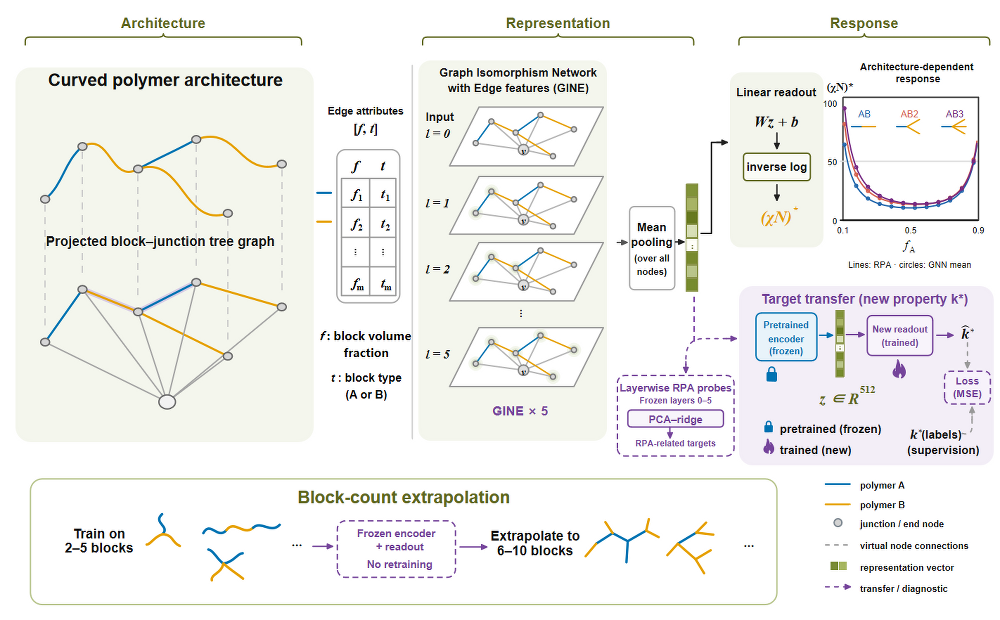

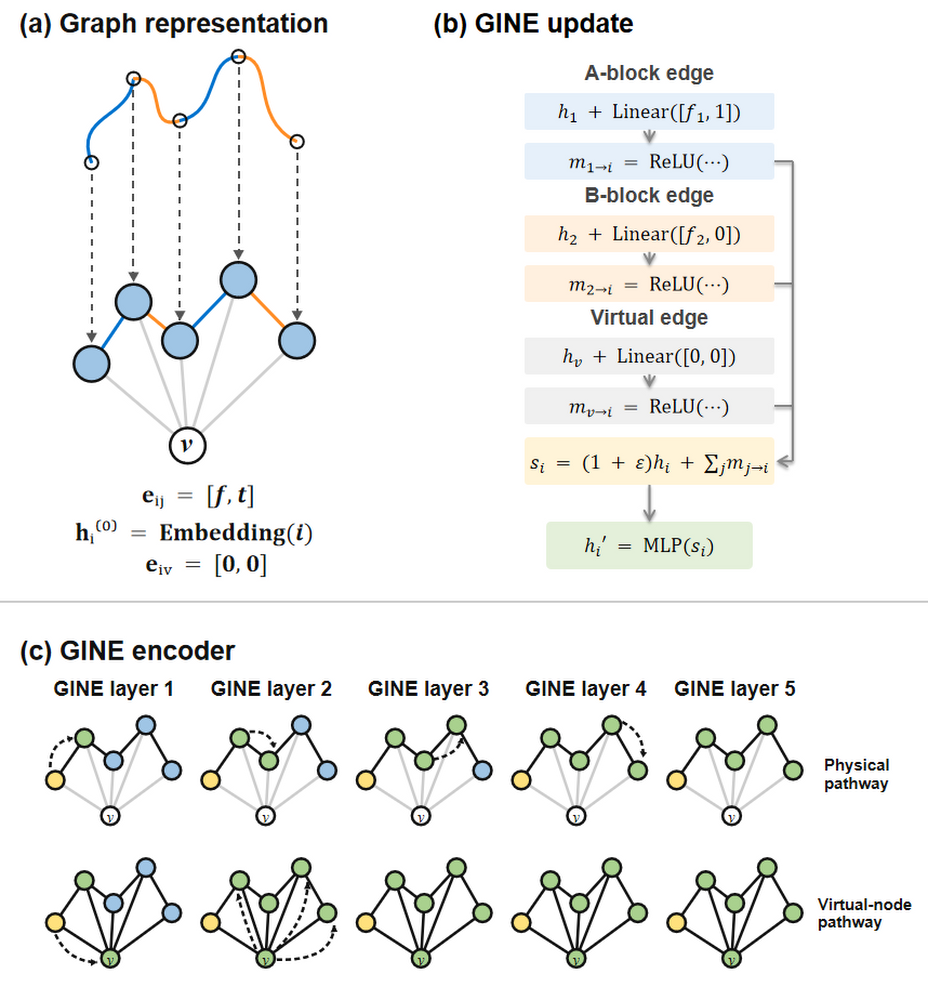

In [1]:
from pathlib import Path
from io import BytesIO
from IPython.display import Image, display
from PIL import Image as PILImage
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
CODE = next(p for base in (cwd, *cwd.parents) for p in (base, base / 'sourcecode/code')
            if (p / 'data/schematics').is_dir())
INPUT = CODE / 'data/schematics'
OUTPUT = CODE / 'results/figures/schematics'
OUTPUT.mkdir(parents=True, exist_ok=True)

def render(source_name, output_name):
    source = INPUT / source_name
    output = OUTPUT / output_name
    with PILImage.open(source) as image:
        image = image.convert('RGB')
        width, height = image.size
        figure = plt.figure(figsize=(width / 100, height / 100), dpi=100, facecolor='white')
        axis = figure.add_axes([0, 0, 1, 1])
        axis.imshow(image, interpolation='lanczos')
        axis.axis('off')
        figure.savefig(output, dpi=600, facecolor='white', bbox_inches=None, pad_inches=0)
        plt.close(figure)
    display(Image(filename=str(output), width=1000))

render('head.png', 'figure1_architecture_representation.png')
render('image.png', 'figure9_gine_encoder.png')